# CAREPILOT — KM Recommendation Benchmark

*Chapter 2 — État de l'art et benchmarking IA · CAREPILOT operational AI*

## 1. Objective

Recommend the most relevant **Knowledge Management (KM) procedure** for an operational ticket using NLP retrieval.

## 2. Problem Type

- **Semantic / lexical retrieval** (not classification)
- Output: top-3 KM procedures with similarity scores

## 3. Dataset Description


- **KM corpus:** `ml_training.km_articles` (~102 articles)
- **Queries:** held-out tickets from `ml_training.historical_tickets`
- **Ground truth:** `expected_km_id` + `relevant_km_ids` (multi-relevant evaluation)

## 4. Preprocessing


- Case normalization, punctuation cleanup, stopword removal (lexical methods)
- Synonym expansion for operational shorthand (POS, SCO, EMV, VLAN)
- Ticket text: title + description + perimeter + category + keywords
- KM text: title + procedure steps + keywords + metadata

## 5. Models / Methods Compared


1. **TF-IDF + Cosine Similarity** — lexical baseline
2. **BM25** — stronger sparse retrieval for short operational queries
3. **Sentence Transformers (`all-MiniLM-L6-v2`)** — semantic embeddings with hybrid reranking


This benchmark compares multiple approaches in order to select the most suitable method for integration into CAREPILOT.

## 6. Evaluation Metrics

Precision@1 · Precision@3 · Recall@3 · MRR · nDCG@3 · Average retrieval time (ms)

## 7. Training or Retrieval Pipeline

Index KM corpus → encode ticket query → rank articles → evaluate top-K hits against ground-truth KM ids.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

NOTEBOOK_DIR = Path.cwd()
ROOT = NOTEBOOK_DIR
for parent in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]:
    if (parent / "ml" / "artifacts").exists():
        ROOT = parent
        break

SHARED = ROOT / "ml" / "notebooks" / "_shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))

from benchmark_notebook_helpers import display_plot, find_project_root, plot_results_table

ROOT = find_project_root()
ARTIFACTS = ROOT / "ml" / "artifacts"
PLOTS = ROOT / "ml" / "plots"
REPORTS = ROOT / "ml" / "reports"
MODELS = ARTIFACTS / "models"

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

RUN_BENCHMARK = False  # Set True to re-train / re-run the full benchmark pipeline



In [2]:
BENCHMARK_SCRIPT = ROOT / "ml/benchmarks/km_recommendation/benchmark.py"
if RUN_BENCHMARK:
    cmd = [sys.executable, str(BENCHMARK_SCRIPT), "--project-root", str(ROOT), *[]]
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True)
else:
    print("Skipping benchmark run (RUN_BENCHMARK=False). Loading saved artifacts.")
    print("Re-run with RUN_BENCHMARK=True or execute:")
    print(f"  python {BENCHMARK_SCRIPT} --project-root {ROOT}")



Skipping benchmark run (RUN_BENCHMARK=False). Loading saved artifacts.
Re-run with RUN_BENCHMARK=True or execute:
  python c:\Users\ar202\carepilot\ml\benchmarks\km_recommendation\benchmark.py --project-root c:\Users\ar202\carepilot


## 8. Benchmark Execution — Load Results

In [3]:
metrics_path = ARTIFACTS / "metrics/km_retrieval_benchmark_metrics.json"
if not metrics_path.exists():
    raise FileNotFoundError(f"Missing metrics artifact: {metrics_path}")
payload = json.loads(metrics_path.read_text(encoding="utf-8"))
rows = payload.get("results", payload.get("methods", []))
results_df = pd.DataFrame(rows)
display(results_df)


,method,precision_at_1,precision_at_3,recall_at_3,mrr,ndcg_at_3,avg_retrieval_time_ms
0,TF-IDF + Cosine,0.7976,0.7791,0.7791,0.8885,0.7648,2.3365
1,BM25,0.8905,0.7887,0.7887,0.9371,0.7945,2.6182
2,Sentence Transformers,0.9324,0.7893,0.7893,0.9594,0.8033,42.0063


## 9. Benchmark Results

Final comparison table (report-ready PNG + DataFrame):

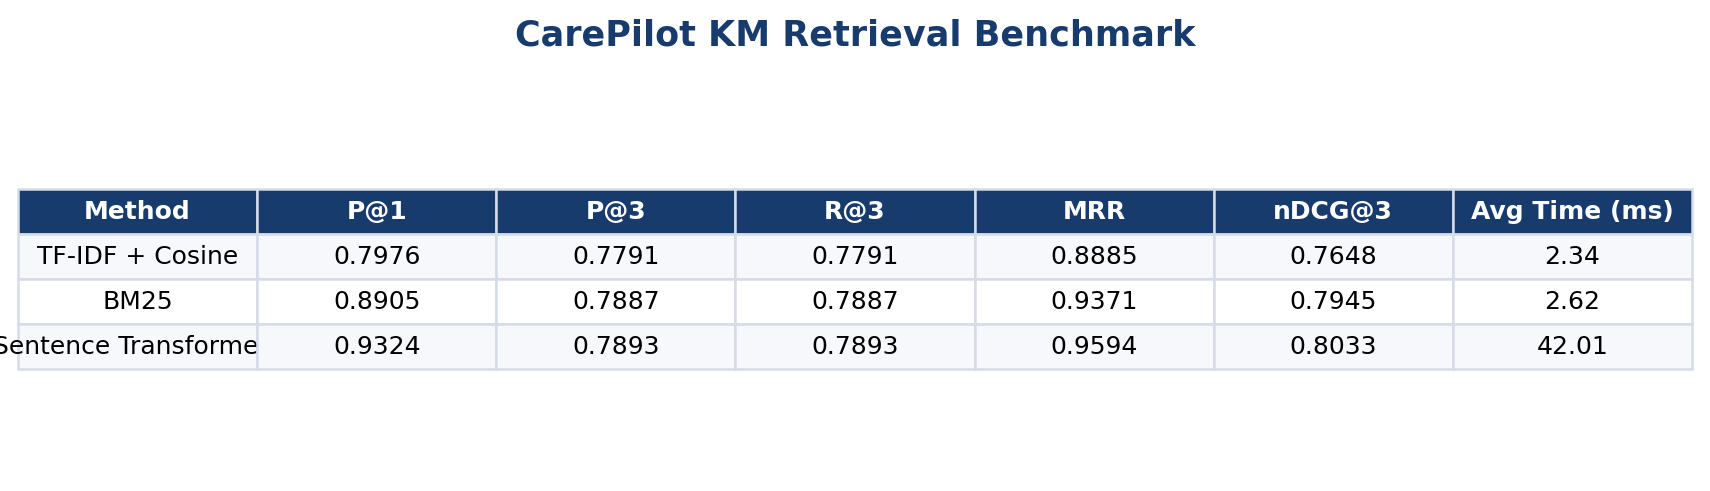

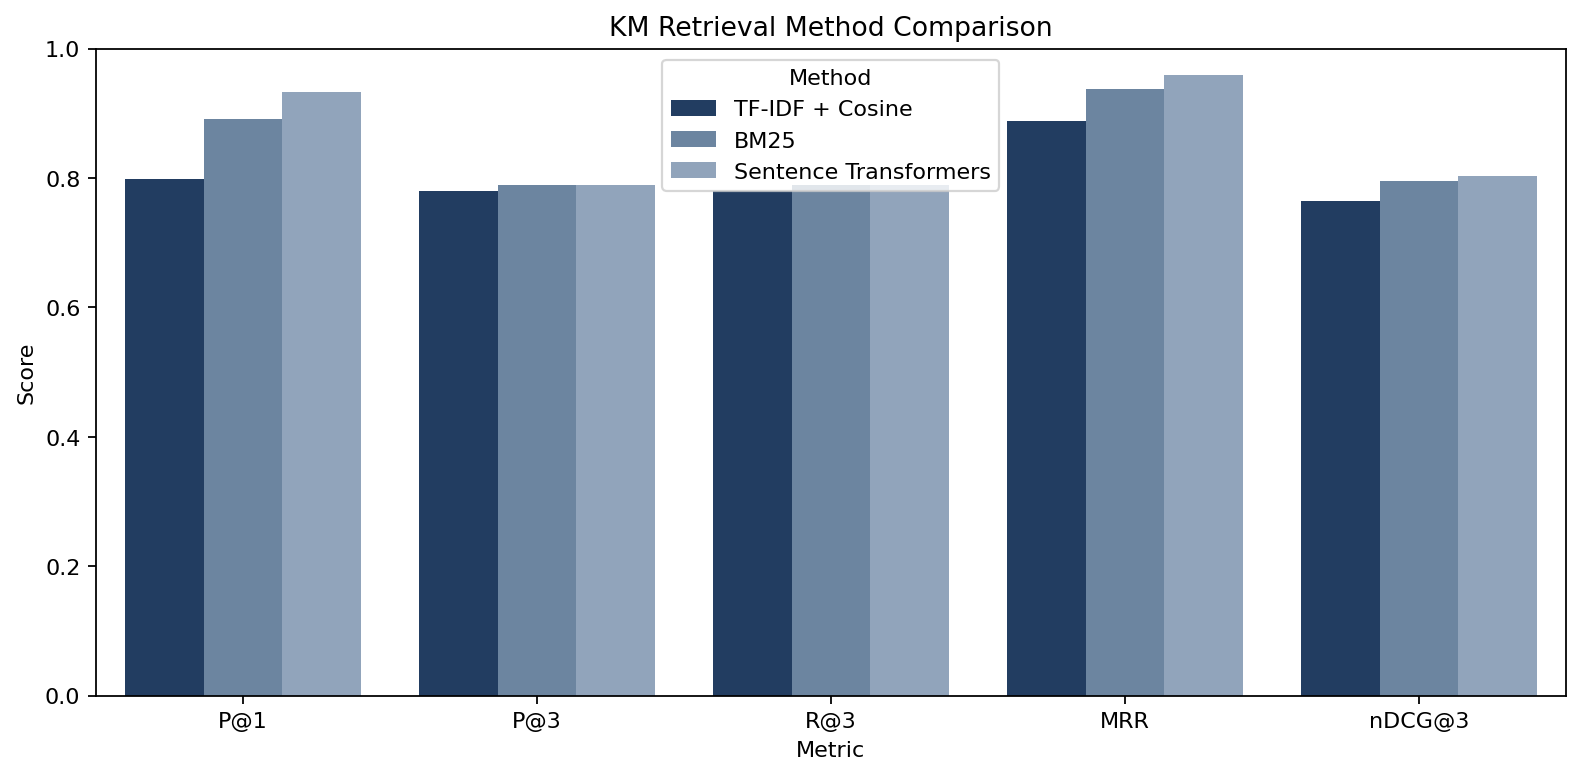

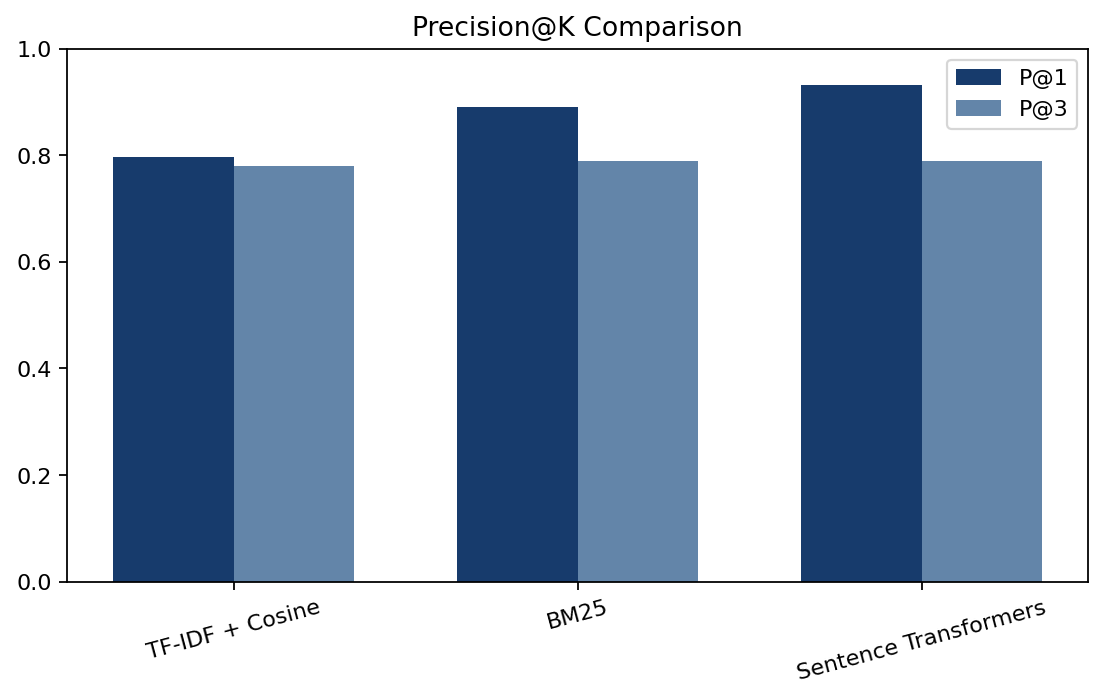

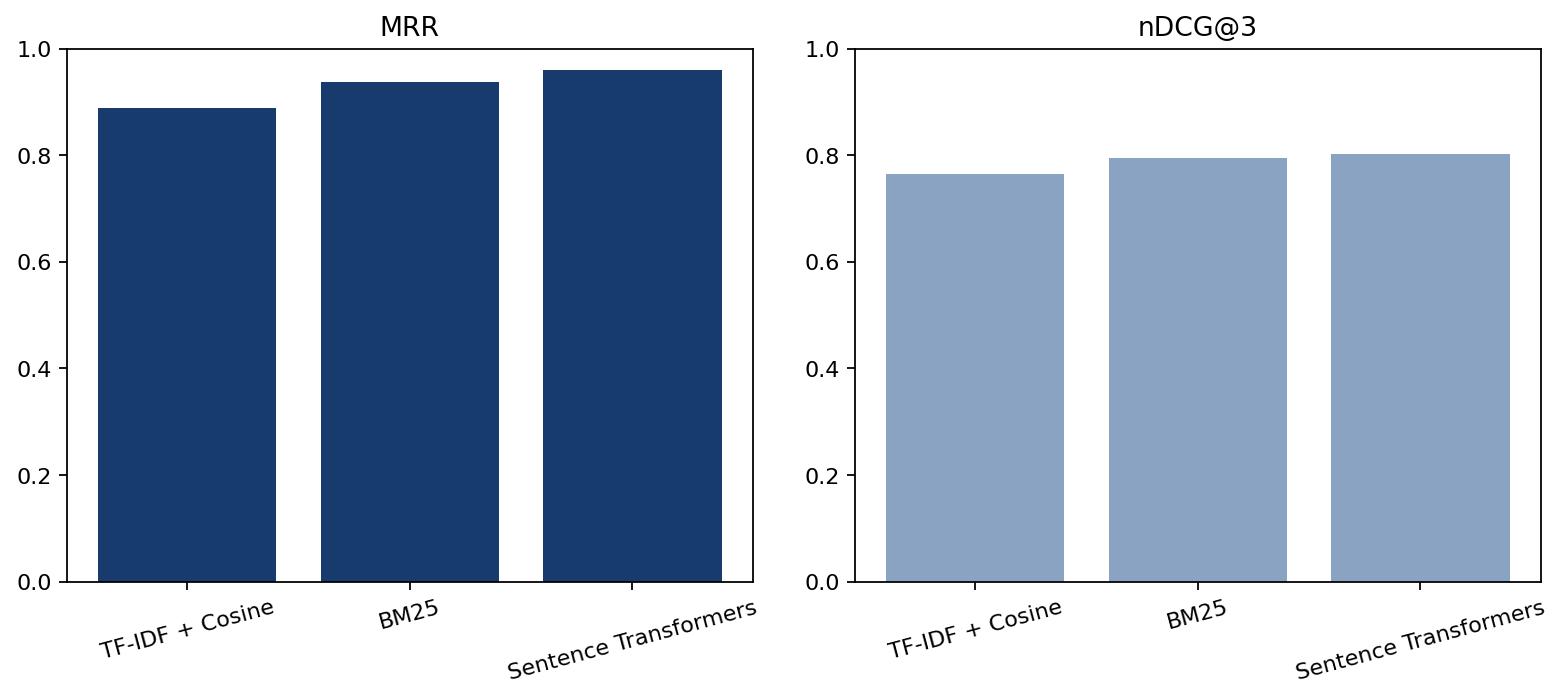

In [4]:
table_png = PLOTS / "03_km_benchmark_results_table.png"
display_plot(table_png)
display_plot(PLOTS / "03_km_method_comparison.png")
display_plot(PLOTS / "03_km_precision_at_k.png")
display_plot(PLOTS / "03_km_mrr_ndcg.png")



## 10. Visualizations

Key plots are loaded from `ml/plots/` (generated by the benchmark pipeline). Re-run with `RUN_BENCHMARK=True` to regenerate.

## 11. Interpretation


Sentence Transformers achieve the highest P@1 (~0.93) and nDCG@3 by capturing paraphrased store wording. BM25 outperforms TF-IDF on short queries. Lexical methods remain useful baselines with lower latency (~2–3 ms vs ~42 ms).

## 12. Selected Model / Method

**Selected for CAREPILOT:**

**Sentence Transformers** — best retrieval quality. Artifact: `ml/artifacts/models/km_retrieval_minilm.joblib`.

## 13. Limitations

- Ambiguous incidents may have multiple valid KM procedures
- Corpus coverage depends on CARE KM sync
- Embedding latency higher than lexical search

## 14. Generated Artifacts

- `ml/artifacts/metrics/km_retrieval_benchmark_metrics.json`
- `ml/plots/03_km_benchmark_results_table.png`
- `ml/reports/03_km_recommendation_benchmark_summary.md`